## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 600
N_LAYER = 8
N_HEAD = 15

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 500
TEMPERATURE = 0.4
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1_a2_encoderdecoder"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")


Configuration loaded.


## 4. Load Tokenizer

In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "tokenizer.json" in files:
        print("Found tokenizer at:", root)

Found tokenizer at: /kaggle/input/datasets/srivenkatm/phase1-simple-data/phase1_simple_data


In [5]:
from transformers import PreTrainedTokenizerFast
import os

DATA_DIR = "/kaggle/input/datasets/srivenkatm/phase1-simple-data/phase1_simple_data"

TOKENIZER_PATH = os.path.join(DATA_DIR, "tokenizer.json")
TRAIN_BIN = os.path.join(DATA_DIR, "train_tokens.bin")
VAL_BIN = os.path.join(DATA_DIR, "val_tokens.bin")

print("Tokenizer exists:", os.path.exists(TOKENIZER_PATH))
print("Train tokens exist:", os.path.exists(TRAIN_BIN))
print("Val tokens exist:", os.path.exists(VAL_BIN))

tokenizer = PreTrainedTokenizerFast(
    tokenizer_file=TOKENIZER_PATH,
    pad_token="<pad>",
    unk_token="<unk>",
    bos_token="<s>",
    eos_token="</s>"
)

print("Vocabulary size:", len(tokenizer))

Tokenizer exists: True
Train tokens exist: True
Val tokens exist: True
Vocabulary size: 50000


## 5. Download Training Data From Hugging Face

In [6]:

# ------------------------------------------------------------
# The tokenizer notebook has ALREADY prepared exactly:
#   200M training token IDs
#   5M validation token IDs
#
# Therefore we do not download and tokenize the raw training JSON again.
# We directly reuse the saved .bin files.
# ------------------------------------------------------------

TRAIN_TOKEN_FILE = os.path.join(DATA_DIR, "train_tokens.bin")
VAL_TOKEN_FILE = os.path.join(DATA_DIR, "val_tokens.bin")

print("Training token file:")
print(TRAIN_TOKEN_FILE)

print("Validation token file:")
print(VAL_TOKEN_FILE)


Training token file:
/kaggle/input/datasets/srivenkatm/phase1-simple-data/phase1_simple_data/train_tokens.bin
Validation token file:
/kaggle/input/datasets/srivenkatm/phase1-simple-data/phase1_simple_data/val_tokens.bin


## 6. Create Train and Validation Tokens Set

In [7]:

import numpy as np

# ------------------------------------------------------------
# Memory-map the token files.
#
# np.memmap is useful here because 200M token IDs are large.
# It reads small pieces from disk only when they are needed,
# instead of loading the whole file into RAM.
#
# uint16 is enough because our vocabulary is about 50k,
# and 50,000 < 65,536.
# ------------------------------------------------------------

train_tokens = np.memmap(
    TRAIN_TOKEN_FILE,
    dtype=np.uint16,
    mode="r",
    shape=(TRAIN_TOKENS,)
)

val_tokens = np.memmap(
    VAL_TOKEN_FILE,
    dtype=np.uint16,
    mode="r",
    shape=(VAL_TOKENS,)
)

print(f"Train tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")


Train tokens: 200,000,000
Validation tokens: 5,000,000


## 7. Create Token Blocks

In [8]:

from torch.utils.data import Dataset

# We keep the full block length = 2048.
# First 1536 tokens become encoder input.
# Last 512 tokens become decoder target.
SOURCE_LENGTH = 1536
TARGET_LENGTH = 512

assert SOURCE_LENGTH + TARGET_LENGTH == TRAIN_BLOCK_SIZE


class Seq2SeqBlockDataset(Dataset):
    """
    Split each 2048-token block into:
        source = first 1536 tokens
        target = final 512 tokens

    This gives the encoder a context and asks the decoder
    to generate the continuation.
    """

    def __init__(self, tokens):
        self.tokens = tokens
        self.num_blocks = len(tokens) // TRAIN_BLOCK_SIZE

    def __len__(self):
        return self.num_blocks

    def __getitem__(self, index):
        start = index * TRAIN_BLOCK_SIZE
        end = start + TRAIN_BLOCK_SIZE

        block = np.array(
            self.tokens[start:end],
            dtype=np.int64
        )

        source = block[:SOURCE_LENGTH]
        target = block[SOURCE_LENGTH:]

        return {
            "input_ids": torch.tensor(source, dtype=torch.long),
            "labels": torch.tensor(target, dtype=torch.long)
        }

print("Encoder-decoder block dataset class created.")


Encoder-decoder block dataset class created.


## 8. Create Datasets

In [9]:

train_dataset = Seq2SeqBlockDataset(train_tokens)
val_dataset = Seq2SeqBlockDataset(val_tokens)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))

print("Encoder input length:", SOURCE_LENGTH)
print("Decoder target length:", TARGET_LENGTH)


Training sequences: 97656
Validation sequences: 2441
Encoder input length: 1536
Decoder target length: 512


## 9. Define The Model

In [10]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.modeling_outputs import Seq2SeqLMOutput

# ============================================================
# ARCHITECTURE 2: ENCODER-DECODER TRANSFORMER (FROM SCRATCH)
# ============================================================

class EncoderBlock(nn.Module):
    """Self-attention + feed-forward encoder block."""

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()

        self.norm1 = nn.LayerNorm(d_model)
        self.self_attention = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True
        )

        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        z = self.norm1(x)
        attention_output, _ = self.self_attention(
            z, z, z,
            need_weights=False
        )
        x = x + self.dropout(attention_output)

        z = self.norm2(x)
        x = x + self.dropout(self.feed_forward(z))

        return x


class Seq2SeqDecoderBlock(nn.Module):
    """Causal self-attention + cross-attention + feed-forward."""

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()

        self.norm1 = nn.LayerNorm(d_model)
        self.self_attention = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True
        )

        self.norm2 = nn.LayerNorm(d_model)
        self.cross_attention = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True
        )

        self.norm3 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, encoder_output, causal_mask):
        # 1. Causal decoder self-attention.
        z = self.norm1(x)
        self_output, _ = self.self_attention(
            z, z, z,
            attn_mask=causal_mask,
            need_weights=False
        )
        x = x + self.dropout(self_output)

        # 2. Cross-attention.
        # Query = decoder, Key/Value = encoder output.
        z = self.norm2(x)
        cross_output, _ = self.cross_attention(
            z,
            encoder_output,
            encoder_output,
            need_weights=False
        )
        x = x + self.dropout(cross_output)

        # 3. Feed-forward network.
        z = self.norm3(x)
        x = x + self.dropout(self.feed_forward(z))

        return x


class EncoderDecoderTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        source_length=1536,
        target_length=512,
        d_model=600,
        n_heads=15,
        n_encoder_layers=8,
        n_decoder_layers=8,
        d_ff=2048,
        dropout=0.1
    ):
        super().__init__()

        self.source_length = source_length
        self.target_length = target_length

        # Same token embedding is shared by encoder and decoder.
        self.token_embedding = nn.Embedding(vocab_size, d_model)

        self.source_position = nn.Embedding(source_length, d_model)
        self.target_position = nn.Embedding(target_length, d_model)

        self.encoder_blocks = nn.ModuleList([
            EncoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_encoder_layers)
        ])

        self.decoder_blocks = nn.ModuleList([
            Seq2SeqDecoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_decoder_layers)
        ])

        self.final_norm = nn.LayerNorm(d_model)
        self.output_layer = nn.Linear(d_model, vocab_size, bias=False)

    def encode(self, source_ids):
        _, seq_len = source_ids.shape
        positions = torch.arange(seq_len, device=source_ids.device)

        x = self.token_embedding(source_ids) + self.source_position(positions)

        for block in self.encoder_blocks:
            x = block(x)

        return x

    def decode(self, decoder_ids, encoder_output):
        _, seq_len = decoder_ids.shape
        positions = torch.arange(seq_len, device=decoder_ids.device)

        x = self.token_embedding(decoder_ids) + self.target_position(positions)

        # Decoder cannot see future target tokens.
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=decoder_ids.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        for block in self.decoder_blocks:
            x = block(x, encoder_output, causal_mask)

        x = self.final_norm(x)
        return self.output_layer(x)

    def forward(self, input_ids, labels=None, attention_mask=None):
        encoder_output = self.encode(input_ids)

        loss = None
        logits = None

        if labels is not None:
            # Teacher forcing:
            # labels       = A B C D
            # decoder input= <s> A B C
            bos_column = torch.full(
                (labels.size(0), 1),
                tokenizer.bos_token_id,
                dtype=torch.long,
                device=labels.device
            )

            decoder_input = torch.cat(
                [bos_column, labels[:, :-1]],
                dim=1
            )

            logits = self.decode(decoder_input, encoder_output)

            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1)
            )

        return Seq2SeqLMOutput(loss=loss, logits=logits)


model = EncoderDecoderTransformer(
    vocab_size=len(tokenizer),
    source_length=SOURCE_LENGTH,
    target_length=TARGET_LENGTH,
    d_model=600,
    n_heads=15,
    n_encoder_layers=8,
    n_decoder_layers=8,
    d_ff=2048,
    dropout=0.1
)

model_size = sum(p.numel() for p in model.parameters())
print(f"Model size: {model_size / 1e6:.2f}M parameters")

assert 50_000_000 <= model_size <= 300_000_000


Model size: 135.26M parameters


In [11]:

def data_collator(features):
    """
    All examples already have equal lengths, so the collator
    only needs to stack them into a batch.
    """

    input_ids = torch.stack([
        item["input_ids"]
        for item in features
    ])

    labels = torch.stack([
        item["labels"]
        for item in features
    ])

    return {
        "input_ids": input_ids,
        "labels": labels
    }


## 10. Training Arguments

In [12]:

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=EPOCHS,

    # Smaller physical batch is safer for free Kaggle GPUs.
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    # 8 small batches are accumulated before one optimizer update.
    gradient_accumulation_steps=8,

    learning_rate=3e-4,
    weight_decay=0.1,
    warmup_steps=500,
    lr_scheduler_type="cosine",

    # Same mixed-precision idea as the starter notebook.
    fp16=torch.cuda.is_available(),

    eval_strategy="steps",
    eval_steps=1000,
    logging_steps=100,
    save_steps=1000,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
    logging_dir=os.path.join(OUTPUT_DIR, "logs")
)


`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


## 11. Training

In [13]:

from transformers import Trainer
from transformers.trainer_utils import get_last_checkpoint

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer
)

# Resume from the latest saved Trainer checkpoint if one exists.
# TrainingArguments already saves checkpoints every 1000 optimizer steps.
last_checkpoint = get_last_checkpoint(MODEL_OUTPUT_DIR)

if last_checkpoint is not None:
    print("Resuming training from checkpoint:")
    print(last_checkpoint)
else:
    print("No existing checkpoint found. Starting training from scratch.")

start_time = time.time()

trainer.train(resume_from_checkpoint=last_checkpoint)

training_time = (time.time() - start_time)

tokens_per_epoch = (len(train_dataset) * TRAIN_BLOCK_SIZE)
total_tokens = (tokens_per_epoch * EPOCHS)
tokens_per_second = (total_tokens / training_time)

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")


No existing checkpoint found. Starting training from scratch.


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss
1000,4.888413,4.809544
2000,4.200705,4.157408
3000,3.879242,3.845194
4000,3.704525,3.671825
5000,3.615783,3.581207
6000,3.603567,3.558695


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

Training time: 6.96 hours
Training speed: 7,982 tokens/sec


## 12. Perplexity

In [14]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Validation loss: 3.558656
Validation perplexity: 35.1160


## 13. Plot Training and Validation Loss

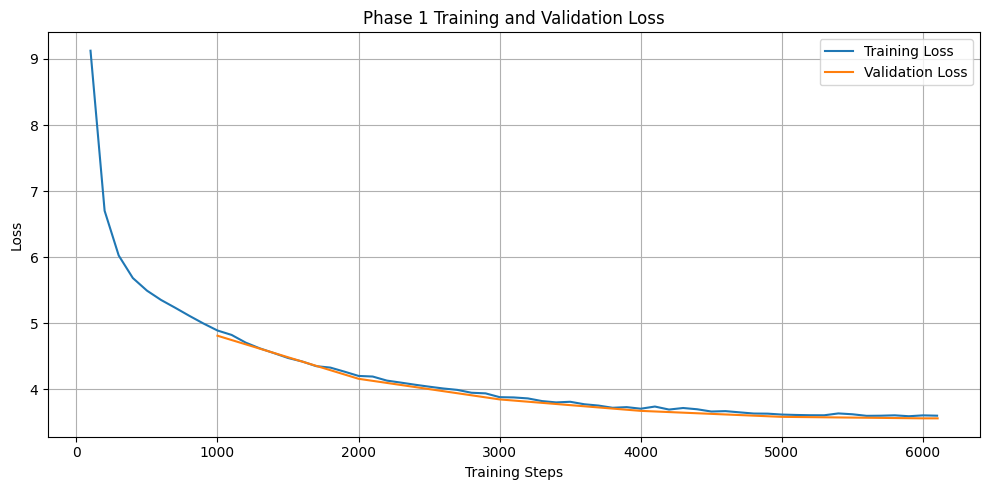

Loss plot saved to:
/kaggle/working/cs781_phase1_a2_encoderdecoder/training_validation_loss.png


In [15]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for log in logs:
    if ("loss" in log and "step" in log):
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if ("eval_loss" in log and "step" in log):
        eval_steps.append(log["step"])
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [16]:

# Save our custom PyTorch architecture weights.
# The tokenizer is saved beside the model so the exact same 50k BPE is reused.
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

torch.save(
    model.state_dict(),
    os.path.join(MODEL_OUTPUT_DIR, "model_state.pt")
)

tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("Saved model and tokenizer to:")
print(MODEL_OUTPUT_DIR)


Saved model and tokenizer to:
/kaggle/working/cs781_phase1_a2_encoderdecoder/legal-gpt2-final


## 15. Push Model to Hugging Face Hub

In [17]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [18]:
from huggingface_hub import hf_hub_download

In [19]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [20]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [21]:

from transformers import PreTrainedTokenizerFast
import torch

generation_tokenizer = PreTrainedTokenizerFast.from_pretrained(
    MODEL_OUTPUT_DIR
)

generation_model = EncoderDecoderTransformer(
    vocab_size=len(generation_tokenizer),
    source_length=SOURCE_LENGTH,
    target_length=TARGET_LENGTH,
    d_model=600,
    n_heads=15,
    n_encoder_layers=8,
    n_decoder_layers=8,
    d_ff=2048,
    dropout=0.1
)

state_dict = torch.load(
    os.path.join(MODEL_OUTPUT_DIR, "model_state.pt"),
    map_location="cpu",
    weights_only=True
)

generation_model.load_state_dict(state_dict)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
generation_model = generation_model.to(device)
generation_model.eval()

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")


Device: cuda
Parameters: 135.26M


## 19. Generate 128 Words
#### (words, not tokens)

In [22]:

def generate_batch(prompts, model, tokenizer, device, target_words=128):
    """Autoregressive generation for our encoder-decoder Transformer."""

    predictions = []

    for prompt in prompts:
        source_ids = tokenizer.encode(
            prompt,
            add_special_tokens=False
        )[-SOURCE_LENGTH:]

        source = torch.tensor(
            [source_ids],
            dtype=torch.long,
            device=device
        )

        with torch.inference_mode():
            # Encoder is run once for the prompt.
            encoder_output = model.encode(source)

            decoder_ids = [tokenizer.bos_token_id]
            generated_ids = []

            for _ in range(MAX_GENERATION_TOKENS):
                current_ids = decoder_ids[-TARGET_LENGTH:]

                decoder_input = torch.tensor(
                    [current_ids],
                    dtype=torch.long,
                    device=device
                )

                logits = model.decode(
                    decoder_input,
                    encoder_output
                )[:, -1, :]

                probs = torch.softmax(logits / TEMPERATURE, dim=-1)

                sorted_probs, sorted_ids = torch.sort(probs, descending=True)
                cumulative = torch.cumsum(sorted_probs, dim=-1)

                remove = cumulative > TOP_P
                remove[:, 1:] = remove[:, :-1].clone()
                remove[:, 0] = False

                sorted_probs[remove] = 0
                sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)

                sampled_index = torch.multinomial(sorted_probs, 1)
                next_token = sorted_ids.gather(1, sampled_index)

                token_id = int(next_token.item())
                decoder_ids.append(token_id)
                generated_ids.append(token_id)

                text = tokenizer.decode(generated_ids, skip_special_tokens=True)
                if len(text.split()) >= target_words:
                    break

        words = tokenizer.decode(
            generated_ids,
            skip_special_tokens=True
        ).split()[:target_words]

        predictions.append(" ".join(words))

    return predictions


## 20. Generate Predictions for the Test Set

In [23]:
predictions = {}
GENERATION_BATCH_SIZE = 32

items = list(test_data.items())
total_examples = len(items)
print(f"Total test examples: {total_examples}")

for start in range(0, total_examples, GENERATION_BATCH_SIZE):
    batch = items[start:start + GENERATION_BATCH_SIZE]
    batch_ids = [str(example_id) for example_id, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=device,
        target_words=128
    )

    for example_id, prediction in zip(batch_ids, batch_predictions):
        predictions[example_id] = {"text": prediction}

    completed = start + len(batch)
    print(f"Completed {completed}/{total_examples} ({100 * completed / total_examples:.1f}%)")

Total test examples: 1000
Completed 32/1000 (3.2%)
Completed 64/1000 (6.4%)
Completed 96/1000 (9.6%)
Completed 128/1000 (12.8%)
Completed 160/1000 (16.0%)
Completed 192/1000 (19.2%)
Completed 224/1000 (22.4%)
Completed 256/1000 (25.6%)
Completed 288/1000 (28.8%)
Completed 320/1000 (32.0%)
Completed 352/1000 (35.2%)
Completed 384/1000 (38.4%)
Completed 416/1000 (41.6%)
Completed 448/1000 (44.8%)
Completed 480/1000 (48.0%)
Completed 512/1000 (51.2%)
Completed 544/1000 (54.4%)
Completed 576/1000 (57.6%)
Completed 608/1000 (60.8%)
Completed 640/1000 (64.0%)
Completed 672/1000 (67.2%)
Completed 704/1000 (70.4%)
Completed 736/1000 (73.6%)
Completed 768/1000 (76.8%)
Completed 800/1000 (80.0%)
Completed 832/1000 (83.2%)
Completed 864/1000 (86.4%)
Completed 896/1000 (89.6%)
Completed 928/1000 (92.8%)
Completed 960/1000 (96.0%)
Completed 992/1000 (99.2%)
Completed 1000/1000 (100.0%)


## 21. Save prediction.json

In [24]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1_a2_encoderdecoder/prediction.json


## 22. Create CodaBench Submission ZIP

In [25]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1_a2_encoderdecoder/submission.zip


In [26]:
import shutil

shutil.make_archive(
    "/kaggle/working/all_working_files",
    "zip",
    "/kaggle/working"
)

print("/kaggle/working/all_working_files.zip")

/kaggle/working/all_working_files.zip


In [27]:
!ls -lh /kaggle/working

total 3.3G
-rw-r--r-- 1 root root 3.3G Oct 11 05:04 all_working_files.zip
drwxr-xr-x 3 root root 4.0K Oct 11 05:01 cs781_phase1_a2_encoderdecoder
-rw-r--r-- 1 root root 117K Oct 11 05:04 __notebook__.ipynb


In [28]:
import os
import shutil

src = "/kaggle/working/cs781_phase1_a2_encoderdecoder"
backup_dir = "/kaggle/working/a2_checkpoint_backup"

if os.path.exists(backup_dir):
    shutil.rmtree(backup_dir)

shutil.copytree(src, backup_dir)

print("Backup folder created:", backup_dir)

Backup folder created: /kaggle/working/a2_checkpoint_backup


In [29]:
!kaggle datasets init -p /kaggle/working/a2_checkpoint_backup

Data package template written to: /kaggle/working/a2_checkpoint_backup/dataset-metadata.json


In [30]:
import json

metadata = {
    "title": "CS781 Architecture 2 Checkpoints",
    "id": "srivenkatm/cs781-architecture2-checkpoints",
    "licenses": [{"name": "CC0-1.0"}]
}

with open(
    "/kaggle/working/a2_checkpoint_backup/dataset-metadata.json",
    "w"
) as f:
    json.dump(metadata, f)

print("Metadata written.")

Metadata written.


In [31]:
!kaggle datasets create \
    -p /kaggle/working/a2_checkpoint_backup \
    --dir-mode zip

Dataset creation error: The requested title "CS781 Architecture 2 Checkpoints" is already in use by a dataset. Please choose another title.
